# Yield Curve (with Inversion)

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Plots government bond yields against maturity for a few dates. The curve's shape (upward, flat or inverted) summarises market expectations for interest rates and growth. Shading where long rates fall below short rates makes inversion visible.

## When to use

- Compare the term structure of interest rates at several points in time
- Explain an inversion (short rates above long rates), often watched as a recession signal
- Provide fixed-income context for asset-allocation or duration decisions

## Avoid when

- Spacing maturities evenly as categories without saying so (1M→3M is not the same gap as 10Y→30Y)
- More than 3–4 dates on one chart (use small multiples or the yield-curve history heatmap)

## Alternatives

- Yield-curve history heatmap
- 10Y–2Y spread line over time

## Design tips

- Use a square-root or log maturity axis so the short end isn't crushed
- Highlight the latest curve and push older ones to gray
- Label the 10Y–2Y spread for each curve, the number readers will look for

## Example

Three stylised US-Treasury-like curves (illustrative values): a normal upward curve, a deeply inverted curve and a partly re-steepened latest curve.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
maturities = ["1M", "3M", "6M", "1Y", "2Y", "3Y", "5Y", "7Y", "10Y", "20Y", "30Y"]
years = np.array([1 / 12, 0.25, 0.5, 1, 2, 3, 5, 7, 10, 20, 30])
curves = pd.DataFrame({
    "Normal": [1.50, 1.60, 1.80, 2.00, 2.30, 2.50, 2.80, 3.00, 3.20, 3.50, 3.60],
    "Inverted": [5.50, 5.45, 5.50, 5.40, 4.90, 4.60, 4.30, 4.20, 4.10, 4.35, 4.20],
    "Latest": [4.30, 4.25, 4.15, 4.00, 3.75, 3.70, 3.80, 3.95, 4.15, 4.60, 4.70],
}, index=pd.Index(maturities, name="maturity"))
curves.loc["spread_10y_2y"] = curves.loc["10Y"] - curves.loc["2Y"]
curves.round(2)

,Normal,Inverted,Latest
maturity,,,
1M,1.5,5.50,4.30
3M,1.6,5.45,4.25
6M,1.8,5.50,4.15
1Y,2.0,5.40,4.00
2Y,2.3,4.90,3.75
3Y,2.5,4.60,3.70
5Y,2.8,4.30,3.80
7Y,3.0,4.20,3.95
10Y,3.2,4.10,4.15


### Plot

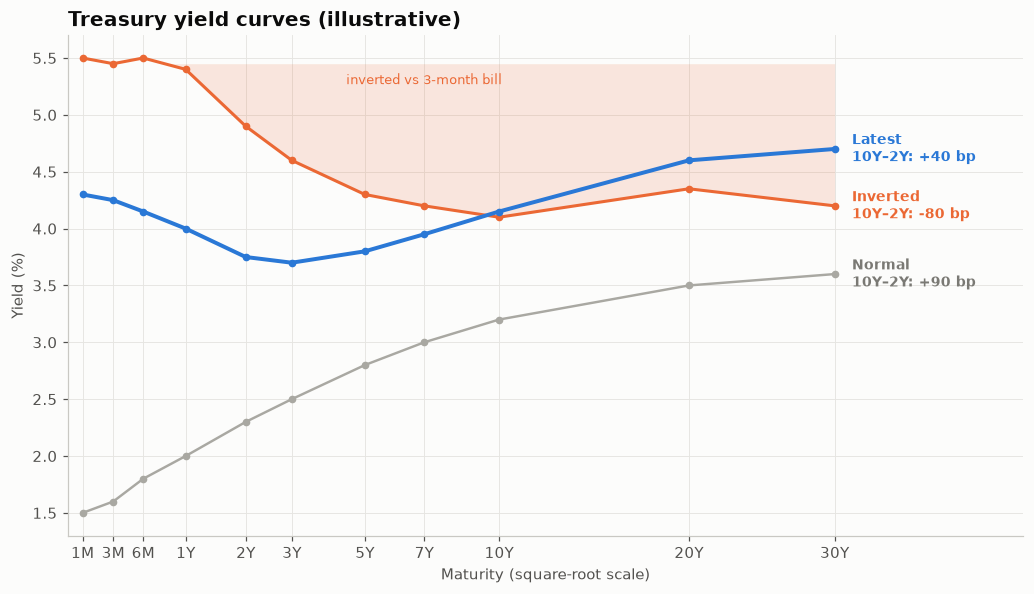

In [3]:
yc = curves.drop(index="spread_10y_2y")
x = np.sqrt(years)                                   # sqrt-maturity axis
styles = {"Normal": ("#a9a8a2", 1.6), "Inverted": (PALETTE[1], 2), "Latest": (PALETTE[0], 2.6)}
fig, ax = plt.subplots(figsize=(9.5, 5.5))
inv = yc["Inverted"].to_numpy()
ax.fill_between(x, inv, inv[1], where=inv < inv[1], interpolate=True, color=PALETTE[1],
                alpha=0.15, linewidth=0)
for name, (color, lw) in styles.items():
    y = yc[name].to_numpy()
    ax.plot(x, y, color=color, linewidth=lw, marker="o", markersize=4)
    spread = curves.loc["spread_10y_2y", name] * 100
    ax.text(x[-1] + 0.12, y[-1], f"{name}\n10Y–2Y: {spread:+.0f} bp", color=color if name != "Normal"
            else "#7a7974", va="center", fontsize=9, fontweight="bold")
ax.text(np.sqrt(7), inv[1] - 0.18, "inverted vs 3-month bill", color=PALETTE[1], fontsize=8.5, ha="center")
ax.set_xticks(x, maturities)
ax.set_xlim(x[0] - 0.1, x[-1] + 1.3)
ax.set_ylabel("Yield (%)")
ax.set_xlabel("Maturity (square-root scale)")
ax.set_title("Treasury yield curves (illustrative)")
fig.tight_layout()
plt.show()

## How to read it

The inverted curve (orange) slopes down: two-year yields sit above ten-year yields, and the shaded area marks the maturities yielding less than 3-month bills. The latest curve (blue) is still inverted at the front but rises beyond five years.

---
Standalone script: [`yield_curve.py`](yield_curve.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)